In [38]:
import pandas as pd
import numpy as np
import yfinance as yf
import plotly.graph_objects as go
from plotly.subplots import make_subplots
from backtesting import Strategy, Backtest
from datetime import datetime, timedelta
from scipy.stats import linregress
from pathlib import Path
import warnings
warnings.filterwarnings("ignore")

In [39]:
df = yf.download("AMZN", period="10y", interval="1d")
df.columns = df.columns.get_level_values(0)
df = df.reset_index()
df['Date'] = pd.to_datetime(df['Date'])
del df['Volume']
df

[*********************100%***********************]  1 of 1 completed


Price,Date,Close,High,Low,Open
0,2016-01-11,30.886999,30.992500,29.928499,30.624001
1,2016-01-12,30.894501,31.299500,30.612000,31.262501
2,2016-01-13,29.090500,31.044001,28.958000,31.044001
3,2016-01-14,29.650000,30.112499,28.493999,29.012501
4,2016-01-15,28.509001,29.231001,28.264999,28.612000
...,...,...,...,...,...
2509,2026-01-02,226.500000,235.460007,224.699997,231.339996
2510,2026-01-05,233.059998,234.000000,227.179993,228.839996
2511,2026-01-06,240.929993,243.179993,232.070007,232.100006
2512,2026-01-07,241.559998,245.289993,239.520004,239.610001


In [40]:
def Donchian(data, n):
    dhi = data.Close.rolling(n).max()
    dlo = data.Close.rolling(n).min()
    dmid = (dhi + dlo) / 2
    return dlo, dmid, dhi

df['Low_D'], df['Mid_D'], df['Up_D'] = Donchian(df, 86)
df.dropna(inplace=True)

In [41]:
def signal(data):
    signal = [0] * len(df)
    for i in range(0,len(df)):
        if (data.Close.iloc[i-1] < data.Up_D.iloc[i-2]) &\
        (data.Close.iloc[i] > data.Up_D.iloc[i-1]):
            signal[i] = 1
        elif (data.Close.iloc[i-1] > data.Low_D.iloc[i-2]) &\
        (data.Close.iloc[i] < data.Low_D.iloc[i-1]):
            signal[i] = 2
        else:
            signal[i] = 0
        df["signal"] = signal  

signal(df)

def up_entries(x):
    offset = 0.002
    if x['signal']==1:
        return x['Low'] * (1-offset)
    else:
        return np.nan

def low_entries(x):
    offset = 0.002
    if x['signal']==2:
        return x['Low'] * (1-offset)
    else:
        return np.nan

df['up_entries'] = df.apply(lambda x: up_entries(x), axis=1)
df['low_entries'] = df.apply(lambda x: low_entries(x), axis=1)
print(df['signal'].value_counts())
df.shape

signal
0    2271
1     125
2      33
Name: count, dtype: int64


(2429, 11)

In [42]:
df.set_index('Date', inplace=True)

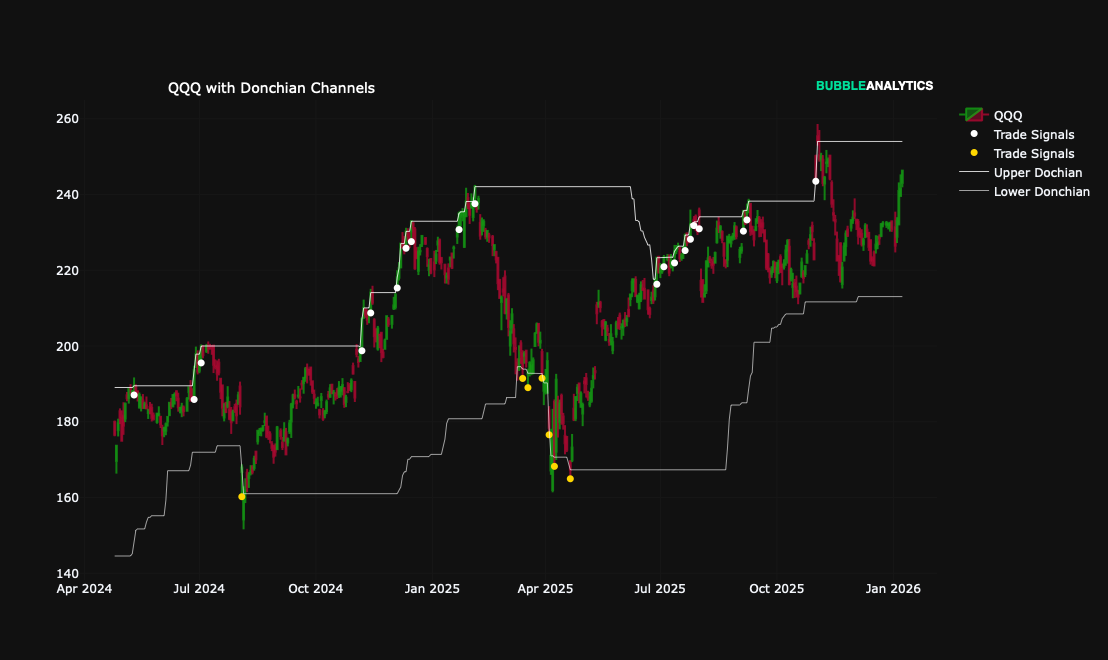

In [43]:
bar = 2000
df1 = df[bar:bar+500].copy()

fig = go.Figure(data=[go.Candlestick(x=df1.index,
                open=df1['Open'],
                high=df1['High'],
                low=df1['Low'],
                close=df1['Close'],
                increasing_line_color = 'rgba(19,156,19,0.8)',
                decreasing_line_color = 'rgba(175,07,49,0.8)',
                name = 'QQQ')])

fig.add_scatter(x=df1.index, y=df1['up_entries'], mode="markers",
                marker=dict(size=7, color="white"),
                name="Trade Signals")

fig.add_scatter(x=df1.index, y=df1['low_entries'], mode="markers",
                marker=dict(size=7, color="gold"),
                name="Trade Signals")

fig.add_trace(go.Scatter(x=df1.index, 
                         y=df1.Up_D, 
                         opacity=0.8, 
                         line=dict(color='white', width=1),
                        name='Upper Dochian'))

fig.add_trace(go.Scatter(x=df1.index, 
                         y=df1.Low_D, 
                         opacity=0.6, 
                         line=dict(color='white', width=1),
                        name='Lower Donchian'))

fig.update_layout(
    annotations=[dict(text="QQQ with Donchian Channels",
                    font=dict(color="white", size=14),
                    xref="paper",
                    yref="paper",
                    x=0.10,
                    y=1.05,
                    showarrow=False)])

fig.update_layout(autosize=False, width=1000, height=660, 
                  xaxis_rangeslider_visible=False, 
                  template="plotly_dark")

fig.update_yaxes(gridcolor="#171717") 
fig.update_xaxes(gridcolor="#171717")

fig.update_xaxes(
    rangebreaks=[
        dict(bounds=["sat", "mon"]),
    ])

GREEN     = "#00DF9A"   
FONT_FAM  = "Atkinson Hyperlegible, Inter, Helvetica, Arial, sans-serif"
BRAND_CORNER = "right"  

bubble_logo = (
    f"<b><span style='color:{GREEN}'>BUBBLE</span>"
    f"<span style='color:white'>ANALYTICS</span></b>"
)

fig.add_annotation(
    text=bubble_logo,
    x=1.0 if BRAND_CORNER == "right" else 0.0,
    y=1.05, xref="paper", yref="paper",
    xanchor="right" if BRAND_CORNER == "right" else "left",
    showarrow=False,
    font=dict(size=12, family=FONT_FAM)
)

#fig.write_image('chart.png', scale=2)

fig.show()


In [54]:
def SIGNAL():
    return df.signal

class MyStrat(Strategy):
    
    def init(self):
        super().init()
        self.signal = self.I(SIGNAL)

    def next(self):
        super().next()
        
        price = self.data.Close[-1]
        
        if self.signal==1: 
            if self.position.is_short or not self.position:
                self.position.close()
                self.buy(size=0.99, tp=1.05*price)
        
        if self.signal==2: 
            if self.position.is_short or not self.position:
                self.position.close()
                self.buy(size=0.99, sl=0.95*price, tp=1.1*price)

bt = Backtest(df, MyStrat, cash=100_000, margin=1, exclusive_orders=True, commission=0.001)
stats = bt.run()
stats

Start                     2016-05-12 00:00:00
End                       2026-01-08 00:00:00
Duration                   3528 days 00:00:00
Exposure Time [%]                    56.93701
Equity Final [$]                 970869.19566
Equity Peak [$]                  970869.19566
Commissions [$]                   40805.29205
Return [%]                           870.8692
Buy & Hold Return [%]               586.11145
Return (Ann.) [%]                    26.59436
Volatility (Ann.) [%]                27.77131
CAGR [%]                             17.62821
Sharpe Ratio                          0.95762
Sortino Ratio                         1.87731
Calmar Ratio                           0.8972
Alpha [%]                           603.08081
Beta                                  0.45689
Max. Drawdown [%]                   -29.64141
Avg. Drawdown [%]                     -3.5386
Max. Drawdown Duration      466 days 00:00:00
Avg. Drawdown Duration       22 days 00:00:00
# Trades                          

In [45]:
results = []

if stats is not None:
            results.append({
                'Start': stats['Start'],
                'End': stats['End'],
                '# Trades': stats['# Trades'],
                'Exposure Time [%]': stats['Exposure Time [%]'],
                'Win Rate [%]': stats['Win Rate [%]'],
                'Return [%]': stats['Return [%]'],
                'Buy & Hold Return [%]': stats['Buy & Hold Return [%]'],
                'Max. Drawdown [%]': stats['Max. Drawdown [%]'],
                'Avg. Drawdown [%]': stats['Avg. Drawdown [%]'],
                'Sharpe Ratio': stats['Sharpe Ratio'],
                'Sortino Ratio': stats['Sortino Ratio'],
                'Calmar Ratio': stats['Calmar Ratio'],
                'Best Trade [%]': stats['Best Trade [%]'],
                'Worst Trade [%]': stats['Worst Trade [%]'],
                'Avg. Trade [%]': stats['Avg. Trade [%]'],
                'Profit Factor': stats['Profit Factor'],
                'Expectancy [%]': stats['Expectancy [%]']
            })

results_df = pd.DataFrame(results)
results_df = results_df.T
results_df.iloc[3:] = results_df.iloc[3:].apply(lambda x: pd.to_numeric(x, errors='coerce').round(2))
#results_df.to_csv('stats.csv', index=True, header=False)

In [46]:
trades = stats['_trades']

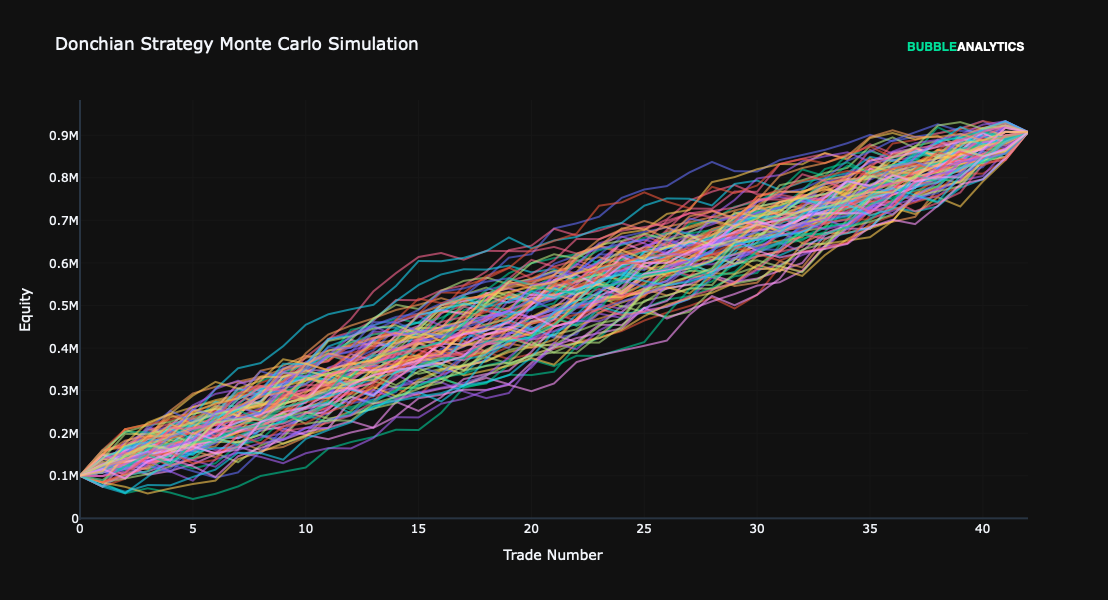

In [47]:
def randomised_trades(trades, cash=100_000):
    equity = [cash]
    for pnl in trades['PnL']:
        equity.append(equity[-1] + pnl)
    return equity

simulations = 100
curves = []

for i in range(simulations):
    new_trades = trades.sample(frac=1).reset_index(drop=True)
    equity_curve = randomised_trades(new_trades)
    curves.append(equity_curve)

mc = go.Figure()

for equity_curve in curves:
    mc.add_trace(go.Scatter(y=equity_curve, mode='lines', opacity=0.6, showlegend=False))

mc.update_layout(
    title='Donchian Strategy Monte Carlo Simulation',
    xaxis_title='Trade Number',
    yaxis_title='Equity',
    template="plotly_dark",
    autosize=False,
    width=1000,
    height=600,
)

mc.update_yaxes(gridcolor="#171717")
mc.update_xaxes(gridcolor="#171717")

GREEN     = "#00DF9A"   
FONT_FAM  = "Atkinson Hyperlegible, Inter, Helvetica, Arial, sans-serif"
BRAND_CORNER = "right"  

bubble_logo = (
    f"<b><span style='color:{GREEN}'>BUBBLE</span>"
    f"<span style='color:white'>ANALYTICS</span></b>"
)

mc.add_annotation(
    text=bubble_logo,
    x=1.0 if BRAND_CORNER == "right" else 0.0,
    y=1.15, xref="paper", yref="paper",
    xanchor="right" if BRAND_CORNER == "right" else "left",
    showarrow=False,
    font=dict(size=12, family=FONT_FAM)
)

#mc.write_image("MC.png", scale=2)

mc.show()

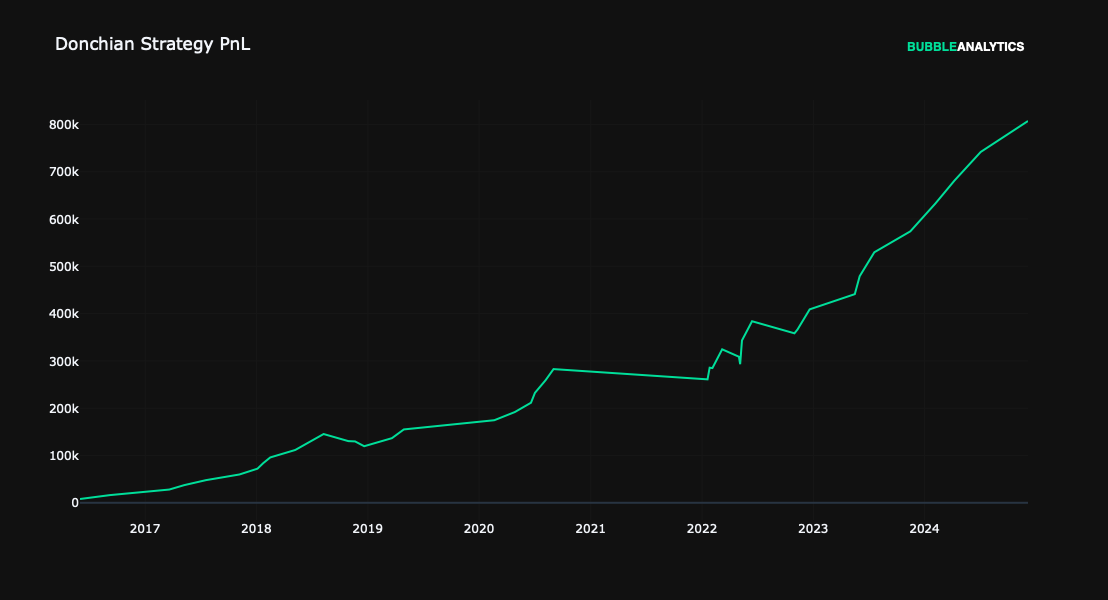

In [48]:
trades['CumulativePnL'] = trades['PnL'].cumsum()

fig_trades = go.Figure()

fig_trades.add_trace(go.Scatter(x=trades['EntryTime'], 
                                      y=trades['CumulativePnL'], 
                                      mode='lines', 
                                      name='Cumulative PnL', 
                                      line=dict(color='#00df9a')))

fig_trades.update_layout(title='Donchian Strategy PnL',
                         template="plotly_dark",
                         autosize=False,
                         width=1000,
                         height=600,
                        )

fig_trades.update_yaxes(gridcolor="#171717")
fig_trades.update_xaxes(gridcolor="#171717")

GREEN     = "#00DF9A"   
FONT_FAM  = "Atkinson Hyperlegible, Inter, Helvetica, Arial, sans-serif"
BRAND_CORNER = "right"  

bubble_logo = (
    f"<b><span style='color:{GREEN}'>BUBBLE</span>"
    f"<span style='color:white'>ANALYTICS</span></b>"
)

fig_trades.add_annotation(
    text=bubble_logo,
    x=1.0 if BRAND_CORNER == "right" else 0.0,
    y=1.15, xref="paper", yref="paper",
    xanchor="right" if BRAND_CORNER == "right" else "left",
    showarrow=False,
    font=dict(size=12, family=FONT_FAM)
)

#fig_trades.write_image("PNL.png", scale=2)

fig_trades.show()

In [49]:

SITE_BG   = "#12181B"  
CARD_BG   = "#161D21"   
ROW_A     = "#141A1E"  
ROW_B     = "#101519" 
BORDER    = "rgba(255,255,255,0.08)" 
TEXT      = "#E6ECEF"   
GREEN     = "#00DF9A"   
FONT_FAM  = "Atkinson Hyperlegible, Inter, Helvetica, Arial, sans-serif"

df = pd.read_csv(
    '/Users/benlockhart/Desktop/Blog Strats/Donchian/stats.csv',
    header=None, names=['Metric', 'Value']
)

metrics = df['Metric'].astype(str).map(lambda s: f"<b>{s}</b>")
values  = df['Value'].astype(str).map(lambda s: f"<b>{s}</b>")

n = len(df)
stripe = [ROW_A if i % 2 == 0 else ROW_B for i in range(n)]
fill   = [stripe, stripe]

fig = go.Figure(data=[
    go.Table(
        columnwidth=[1, 1],
        cells=dict(
            values=[metrics, values],
            align=['left', 'right'],
            height=30,
            font=dict(size=13, color=TEXT, family=FONT_FAM),
            fill_color=fill,
            line_color=BORDER,
            line_width=1
        )
    )
])

fig.update_layout(
    title=dict(
        text="Donchian Strategy Stats",
        font=dict(size=16, color=TEXT, family=FONT_FAM),
        x=0.5, xanchor='right'
    ),
    width=500,
    height=660,
    paper_bgcolor=SITE_BG,
    plot_bgcolor=CARD_BG,
    margin=dict(l=30, r=30, t=90, b=30)
)

BRAND_CORNER = "right"  

bubble_logo = (
    f"<b><span style='color:{GREEN}'>BUBBLE</span>"
    f"<span style='color:white'>ANALYTICS</span></b>"
)

fig.add_annotation(
    text=bubble_logo,
    x=1.0 if BRAND_CORNER == "right" else 0.0,
    y=1.11, xref="paper", yref="paper",
    xanchor="right" if BRAND_CORNER == "right" else "left",
    showarrow=False,
    font=dict(size=12, family=FONT_FAM)
)

fig.add_shape(
    type="rect", xref="paper", yref="paper",
    x0=0, y0=0, x1=1, y1=1,
    line=dict(color=BORDER, width=1),
    fillcolor=CARD_BG, layer="below"
)

fig.show()

#fig.write_image("stats.png", scale=2)

FileNotFoundError: [Errno 2] No such file or directory: '/Users/benlockhart/Desktop/Blog Strats/Donchian/stats.csv'